In [64]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 

In [65]:
#telecharger les S1P500 and BTC from FRED. 
#index_col=0 : la 1re colonne (les dates) devient l'index : chaque ligne est repérée par sa date, et non plus par 0, 1, 2…
#parse_dates=True : les dates sont lues comme de vraies dates, pas comme du texte. Indispensable pour trier, filtrer par période et tracer
#na_values="." : FRED écrit un point les jours fériés sans cotation. On dit à pandas que ce point veut dire « valeur manquante » (NaN)

sp500=pd.read_csv("SP500.csv", index_col=0,parse_dates=True,na_values=".") 
sp500.head()

,SP500
observation_date,
2016-10-31,2126.15
2016-11-01,2111.72
2016-11-02,2097.94
2016-11-03,2088.66
2016-11-04,2085.18


In [66]:
BTC=pd.read_csv("CBBTCUSD.csv", index_col=0, parse_dates=True,na_values=".")
BTC.head()

,CBBTCUSD
observation_date,
2014-12-01,370.0
2014-12-02,378.0
2014-12-03,378.0
2014-12-04,377.1
2014-12-05,NaN


In [67]:
sp500.info()   #general info :  nombre de lignes, type des colonnes, valeurs non manquantes
sp500.isna().sum() #combien de valeurs manquantes


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2609 entries, 2016-10-31 to 2026-10-29
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SP500   2513 non-null   float64
dtypes: float64(1)
memory usage: 40.8 KB


SP500    96
dtype: int64

In [68]:
sp500 = sp500.dropna()        # drop na , supprime valeur manquante

In [69]:
sp500.isna().sum()    #combien de valeurs manquantes

SP500    0
dtype: int64

# Parie 1 : du prix au rendements 

In [85]:
#calcul des rendements normals Rt_sp500
def Rendement_discret(sp500):
    i=1
    Rt_sp500=[]
    for i in range (1,len(sp500)):
       R =((sp500.iloc[i]-sp500.iloc[i-1])/sp500.iloc[i-1])*100
       Rt_sp500.append(R)
    return Rt_sp500
Rt_sp500=Rendement_discret(sp500)
print(Rt_sp500[:5])

[SP500   -0.678692
dtype: float64, SP500   -0.652549
dtype: float64, SP500   -0.442339
dtype: float64, SP500   -0.166614
dtype: float64, SP500    2.22235
dtype: float64]


In [86]:
#calcul des rendements continus ou log : rt(sp500)
def Rendement_continu(sp500):
    i=1
    rt_sp500=[]
    for i in range (1,len(sp500)):
       R =(np.log(sp500.iloc[i])-np.log(sp500.iloc[i-1]))*100
       rt_sp500.append(R)
    return rt_sp500
rt_sp500=Rendement_continu(sp500)
print(rt_sp500[:5])

[SP500   -0.681005
dtype: float64, SP500   -0.654687
dtype: float64, SP500   -0.44332
dtype: float64, SP500   -0.166753
dtype: float64, SP500    2.198016
dtype: float64]


In [87]:
#calcul des rendements normals Rt_BTC
def Rendement_discret(BTC):
    i=1
    Rt_BTC=[]
    for i in range (1,len(BTC)):
       R =((BTC.iloc[i]-BTC.iloc[i-1])/BTC.iloc[i-1])*100
       Rt_BTC.append(R)
    return Rt_BTC
Rt_BTC=Rendement_discret(BTC)
print(Rt_BTC[:10])

[CBBTCUSD    2.162162
dtype: float64, CBBTCUSD    0.0
dtype: float64, CBBTCUSD   -0.238095
dtype: float64, CBBTCUSD   NaN
dtype: float64, CBBTCUSD   NaN
dtype: float64, CBBTCUSD   NaN
dtype: float64, CBBTCUSD   NaN
dtype: float64, CBBTCUSD   NaN
dtype: float64, CBBTCUSD   NaN
dtype: float64, CBBTCUSD   NaN
dtype: float64]


In [88]:
#calcul des rendements continus ou log : rt_BTC
def Rendement_continu(BTC):
    i=1
    rt_BTC=[]
    for i in range (1,len(BTC)):
       R =(np.log(BTC.iloc[i])-np.log(BTC.iloc[i-1]))*100
       rt_BTC.append(R)
    return rt_BTC
rt_BTC=Rendement_continu(BTC)
print(rt_BTC[:10])

[CBBTCUSD    2.139119
dtype: float64, CBBTCUSD    0.0
dtype: float64, CBBTCUSD   -0.238379
dtype: float64, CBBTCUSD   NaN
dtype: float64, CBBTCUSD   NaN
dtype: float64, CBBTCUSD   NaN
dtype: float64, CBBTCUSD   NaN
dtype: float64, CBBTCUSD   NaN
dtype: float64, CBBTCUSD   NaN
dtype: float64, CBBTCUSD   NaN
dtype: float64]


Le S&P 500 cote 5 jours par semaine, hors jours fériés américains. Le Bitcoin cote tous les jours, week-ends compris. Pour comparer les deux le même jour, on ne garde que les dates communes :

In [89]:
#élimine seulement les jours où le Bitcoin cote seul : les week-ends et les jours fériés américains.
#join assemble deux tableaux côte à côte en alignant leurs index, ici les date
#• how="inner" ne garde que les dates présentes dans les deux tableaux.
#on clacule les prix fusionees des date sou BTC et sp500 sont cote puis on calcule el rendement 
prix = sp500.join(BTC, how="inner").dropna()  
prix.columns = ["sp500", "BTC"]
#calcul des rendements normals Rt
def Rendement_discret(prix):
    i=1
    Rt=[]
    for i in range (1,len(prix)):
       R =((prix.iloc[i]-prix.iloc[i-1])/prix.iloc[i-1])*100
       Rt.append(R)
    return Rt
Rt=Rendement_discret(prix)
print(Rt[:5])

[sp500   -0.678692
BTC      4.850050
dtype: float64, sp500   -0.652549
BTC      1.902285
dtype: float64, sp500   -0.442339
BTC     -7.332796
dtype: float64, sp500   -0.166614
BTC      2.365217
dtype: float64, sp500    2.222350
BTC      0.014158
dtype: float64]


In [90]:
#Rt en data frame avec date
Rt = pd.DataFrame(Rt, index=prix.index[1:])
Rt.head()

,sp500,BTC
observation_date,,
2016-11-01,-0.678692,4.850050
2016-11-02,-0.652549,1.902285
2016-11-03,-0.442339,-7.332796
2016-11-04,-0.166614,2.365217
2016-11-07,2.222350,0.014158


In [91]:
Rt.describe()

,sp500,BTC
count,2511.000000,2511.000000
mean,0.057887,0.276613
std,1.139934,4.201908
min,-11.984050,-37.413755
25%,-0.375857,-1.595492
50%,0.080801,0.158738
75%,0.589883,2.031780
max,9.515390,27.201980


# Partie 2: volatilité et graphiques dans le temps

In [92]:
#On prend N = 252 jours pour les actions, et 365 pour le Bitcoin quand on travaille sur sa série complète, puisqu'il cote tous les jours.
std_jour=Rt.std()
std_an=Rt.std()*np.sqrt(252)
#mettre en data frame
Std = pd.DataFrame({ "Volatilité journalière (%)": Rt.std(), "Volatilité annuelle (%)": Rt.std() * np.sqrt(252),
})
Std.round(2)

,Volatilité journalière (%),Volatilité annuelle (%)
sp500,1.14,18.1
BTC,4.20,66.7


In [93]:
# pour chaque date, on calcule l'écart-type des 30 derniers rendements
Std_gliss=Rt.rolling(30).std() * np.sqrt(252)
Std_gliss.columns = ["Vol. glissante S&P 500 (%)", "Vol. glissante BTC (%)"]
Std_gliss.round(2)


,Vol. glissante S&P 500 (%),Vol. glissante BTC (%)
observation_date,,
2016-11-01,NaN,NaN
2016-11-02,NaN,NaN
2016-11-03,NaN,NaN
2016-11-04,NaN,NaN
2016-11-07,NaN,NaN
...,...,...
2026-10-23,10.43,34.77
2026-10-26,10.52,34.86
2026-10-27,10.55,33.42


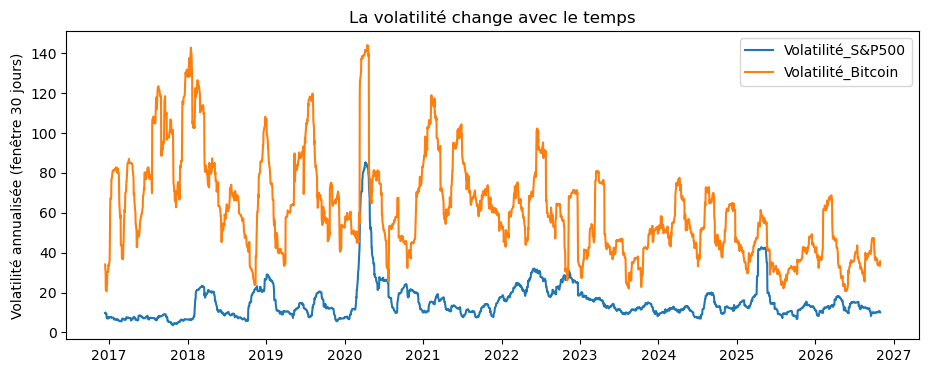

In [94]:
#tracer série dans le temps 
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(Std_gliss.index, Std_gliss["Vol. glissante S&P 500 (%)"], label="Volatilité_S&P500")
ax.plot(Std_gliss.index, Std_gliss[ "Vol. glissante BTC (%)"], label="Volatilité_Bitcoin")
ax.set_ylabel("Volatilité annualisée (fenêtre 30 jours)")
ax.set_title("La volatilité change avec le temps")
ax.legend()
plt.show()

-Pic nets en Mars 2020
-BTC beaucoup plus volatile que S&P500

# Partie 3 : VaR historique et corrélation en crise

In [109]:
#Calcule de la value at risk historique 

perte_sp500=-Rt
VaRh_sp500=perte_sp500.quantile(0.99)
ES_sp500=perte_sp500[perte_sp500>VaRh_sp500].mean()
perte_BTC=-Rt
VaRh_BTC=perte_BTC.quantile(0.99)
ES_BTC=perte_BTC[perte_BTC>VaRh_BTC].mean()
Observ=pd.DataFrame({"VaRH_SP500":VaRh_sp500,"ES_SP500":ES_sp500,"VarH_BTC":VaRh_BTC,"ES_BTC": ES_BTC})
Observ.round(2)

,VaRH_SP500,ES_SP500,VarH_BTC,ES_BTC
sp500,3.34,4.76,3.34,4.76
BTC,11.40,14.92,11.40,14.92


In [118]:
#La VaR normale (paramétrique) : La méthode qui suppose une loi normale, avec la volatilité observée

from scipy.stats import norm
#norm.ppf(0.99) donne  : la position du quantile 99 % d'une loi normale.
VaR_norm = norm.ppf(0.99) * Rt.std()

Observ_norm=pd.DataFrame({"VaR-norm":VaR_norm,"VarH":(-Rt).quantile(0.99)})
Observ_norm.round(2)

,VaR-norm,VarH
sp500,2.65,3.34
BTC,9.78,11.40


La VaR normale sous-estime le risque, pour les deux actifs. Les vraies pertes extrêmes sont plus fortes que ce que prévoit la loi normale : ce sont les queues épaisses. La réponse à la question de l’exercice est donc : non, la VaR normale n’est pas prudente.

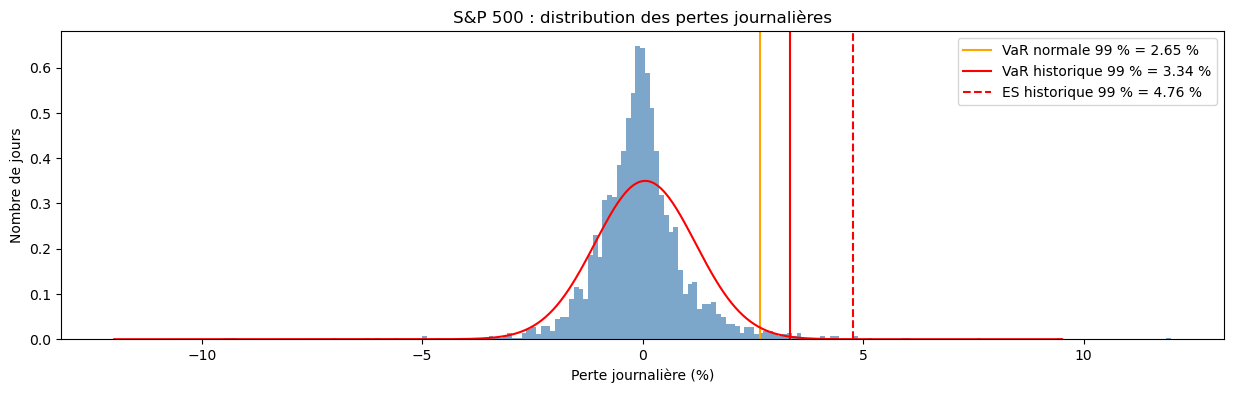

In [137]:
#density =True allows la superposition de deux graphes
perte_sp500=-Rt["sp500"]

fig, ax = plt.subplots(figsize=(15, 4))
ax.hist(perte_sp500, bins=200, color="steelblue",density=True, alpha=0.7)
ax.axvline(VaR_norm["sp500"], color="orange", label=f"VaR normale 99 % = {VaR_norm["sp500"]:.2f} %")
ax.axvline(VaRh_sp500["sp500"], color="red", label=f"VaR historique 99 % = {VaRh_sp500["sp500"]:.2f} %")
ax.axvline(ES_sp500["sp500"], color="red", linestyle="--", label=f"ES historique 99 % = {ES_sp500["sp500"]:.2f} %")
ax.set_title("S&P 500 : distribution des pertes journalières")
ax.set_xlabel("Perte journalière (%)")
ax.set_ylabel("Nombre de jours")

x = np.linspace(Rt["sp500"].min(), Rt["sp500"].max(), 500)
y = norm.pdf(x, Rt["sp500"].mean(), Rt["sp500"].std())
plt.plot(x, y, color="red")

ax.legend()
plt.show()

C’est justement là que la loi normale se trompe. À droite de la ligne orange, la courbe rouge s’éteint, mais les barres bleues continuent jusqu’à 5 % et au-delà. Dans la réalité, plus de 1 % des jours dépassent 2,65 % de perte. Pour retrouver exactement 1 % des vrais jours, il faut aller jusqu’à 3,34 % : c’est la ligne rouge pleine, la VaR historique.

 backtesting : dépassement c'est le nombre de jours où la vraie perte a été plus grande que la VaR .Si une VaR 99 % est juste, la perte doit la dépasser environ 1 jour sur 100.


In [140]:
#Nbre de dépassment avec la Var Nomale
nb_jours = len(perte_sp500)
print((perte_sp500 > VaR_norm["sp500"]).sum(), "dépassements, pour", nb_jours * 0.01, "attendus")


48 dépassements, pour 25.11 attendus


Sur la période étudiée, environ 2 500 jours de cotation, la VaR normale à 99 % du S&P 500 (2,65 %) a été dépassée 48 fois, alors qu’une VaR correctement calibrée ne devrait l’être qu’environ 25 fois, soit 1 % des jours. Le taux de dépassement observé, environ 1,9 %, est presque le double du taux attendu.

Cet écart est trop important pour s’expliquer par le hasard : la VaR fondée sur la loi normale sous-estime systématiquement les pertes extrêmes. Ce résultat est cohérent avec la VaR historique, plus élevée (3,34 %), et avec l’histogramme des pertes, qui montre des queues plus épaisses que celles de la loi normale.

En pratique, une banque qui utiliserait ce modèle pour calculer ses fonds propres serait insuffisamment protégée lors des journées de crise. Le modèle devrait être recalibré, par exemple avec une loi à queues épaisses comme la loi de Student, ou remplacé par une VaR historique.

In [141]:
#Nbre de dépassement avec VaR historique:
nb_jours = len(perte_sp500)
print((perte_sp500 > VaRh_sp500["sp500"]).sum(), "dépassements, pour", nb_jours * 0.01, "attendus")

26 dépassements, pour 25.11 attendus


In [ ]:
La VaR historique détécte mieux les dépassements. 

In [146]:
#La corrélation, en temps normal et en crise
Rt.corr()                                   # sur toute la période
Rt.loc["2020-02-15":"2020-04-30"].corr()    # pendant le krach du Covid
corr_60j = Rt["sp500"].rolling(60).corr(Rt["BTC"])   # dans le temps
print(Rt.corr())
print (Rt.loc["2020-02-15":"2020-04-30"].corr())
print(corr_60j)

          sp500       BTC
sp500  1.000000  0.224268
BTC    0.224268  1.000000
          sp500       BTC
sp500  1.000000  0.558164
BTC    0.558164  1.000000
observation_date
2016-11-01         NaN
2016-11-02         NaN
2016-11-03         NaN
2016-11-04         NaN
2016-11-07         NaN
                ...   
2026-10-23    0.387088
2026-10-26    0.405336
2026-10-27    0.413759
2026-10-28    0.435554
2026-10-29    0.439375
Length: 2511, dtype: float64


# Partie 4 :  les faits stylisés en images

Quatre graphiques classiques décrivent le comportement des rendements : volatilité mensuelle, autocorrélation, Q-Q normal et nuages de points.

In [151]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy import stats

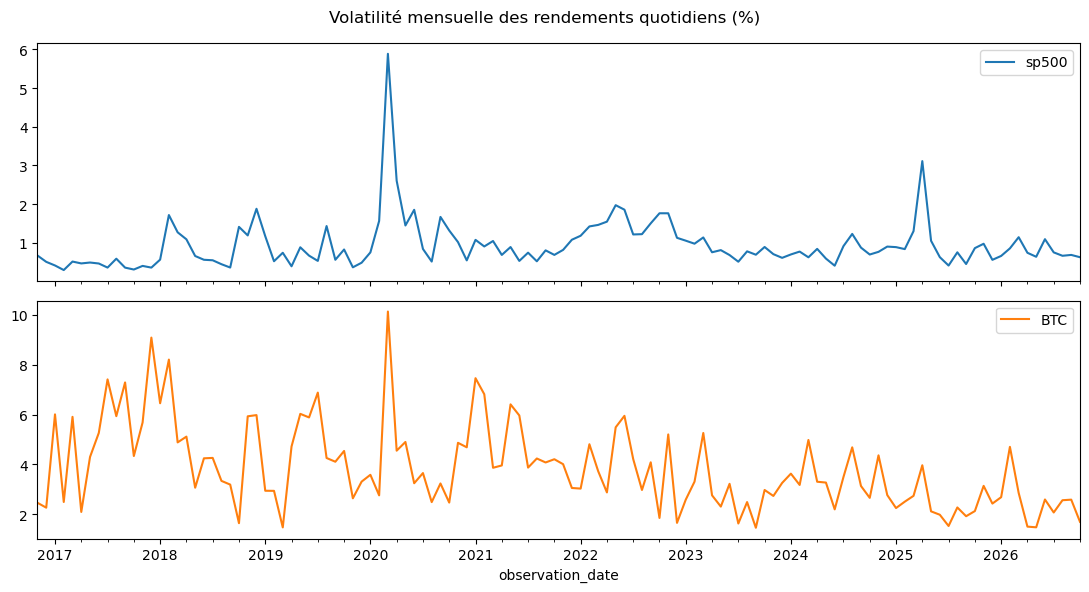

In [152]:
#1) Volatilité mensuelle 
# subplots=True trace chaque actif dans son propre graphique, empilés.
volatilité_mensuelle = Rt.resample("ME").std() #resample("ME") regroupe les jours par mois, "ME" pour month end
volatilité_mensuelle.plot(subplots=True, figsize=(11, 6),title="Volatilité mensuelle des rendements quotidiens (%)")
plt.tight_layout()
plt.show()

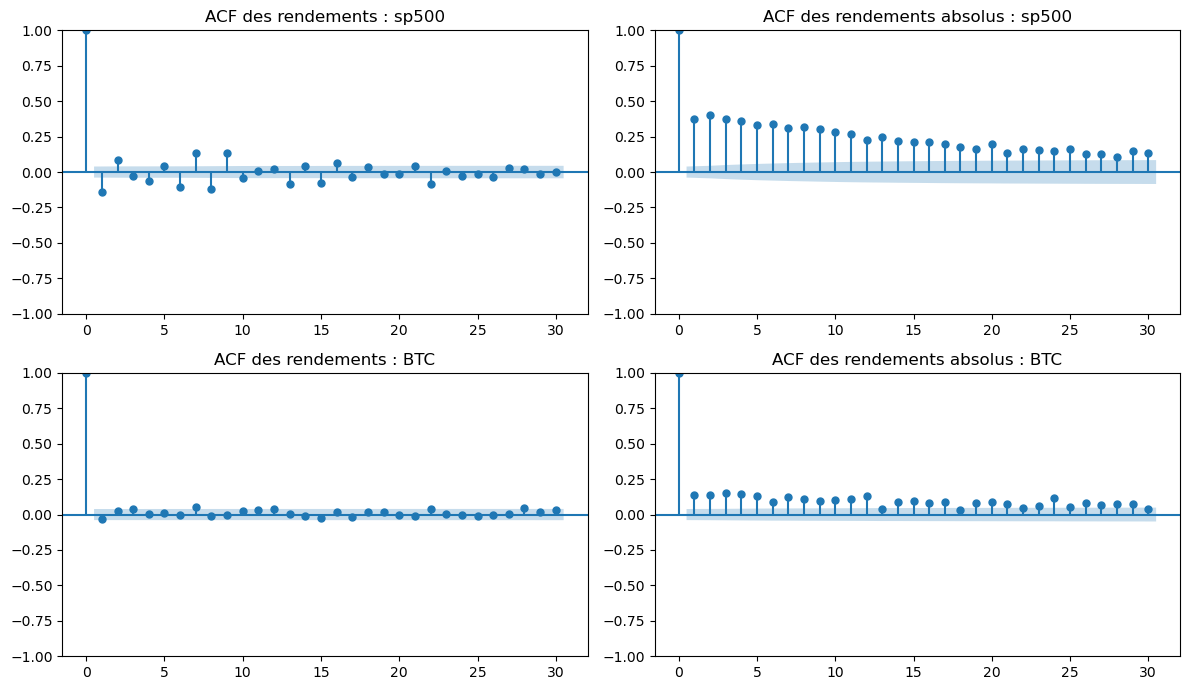

In [155]:
#2) Fonction d'autocorrélation (ACF)
#L’autocorrélation, c’est la corrélation d’une série avec elle-même, décalée dans le temps. Elle répond à la question : « ce qui s’est passé hier aide-t-il à prévoir aujourd’hui ?
#On compare la série du jour avec celle de la veille, c’est le retard 1 (lag 1)
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for i, col in enumerate(["sp500", "BTC"]):
    plot_acf(Rt[col], lags=30, ax=axes[i, 0], title=f"ACF des rendements : {col}")
    plot_acf(Rt[col].abs(), lags=30, ax=axes[i, 1], title=f"ACF des rendements absolus : {col}")
plt.tight_layout()
plt.show()

# Règle : on n’interprète que les barres qui sortent de la zone.
#La zone bleutée est l’intervalle de confiance à 95 % : c’est la zone du hasard.

L’idée

Même si une série n’avait aucune autocorrélation réelle, son ACF calculée sur des données ne donnerait jamais exactement 0 : de petites corrélations apparaîtraient par pur hasard, comme quand on lance une pièce 100 fois et qu’on obtient 53 piles au lieu de 50.

La zone bleutée indique jusqu’où ces fluctuations dues au hasard peuvent aller.

Pour S&P500
À gauche : les rendements

Ce qu’on voit : les barres sont petites, entre −0,14 et +0,14, mais plusieurs sortent de la zone bleutée : au retard 1 (environ −0,14), puis aux retards 2, 6, 7, 8 et 9. Leurs signes alternent : négatif, positif, négatif…

Ce que ça veut dire :

Le retard 1 est négatif : une baisse un jour tend à être suivie d’une légère hausse le lendemain, et inversement. C’est un effet de retour en arrière, souvent observé après de fortes secousses.
Ces autocorrélations restent faibles : 0,14 au maximum. Elles ne permettent pas vraiment de prévoir le rendement de demain, surtout après les coûts de transaction.
Elles viennent surtout des crises. En mars 2020, le S&P 500 a enchaîné des journées de −10 % et de +9 % en alternance. Ces quelques journées extrêmes suffisent à créer ces barres. Le test lui-même suppose une volatilité constante, ce qui n’est pas le cas ici.

C’est cohérent avec ton test de Ljung-Box en R, qui rejetait aussi l’indépendance des rendements quotidiens du S&P 500.

À droite : les rendements absolus

Ce qu’on voit : toutes les barres sont positives et très au-dessus de la zone bleutée : environ 0,37 au retard 1, 0,40 au retard 2, puis une décroissance très lente, encore autour de 0,13 après 30 jours.

Ce que ça veut dire :

Le regroupement d'autocorrélation est très fort. Un jour agité est suivi de jours agités, et un jour calme de jours calmes.
La mémoire est longue. Même un mois et demi de bourse plus tard, l’agitation passée influence encore celle d’aujourd’hui. Une crise ne se calme pas en quelques jours : elle s’étire sur des semaines.

Pour BTC: 

toutes les barres sont dans la zone : on ne détecte aucune autocorrélation. Les rendements du Bitcoin ne permettent pas de prévoir sa direction. C’est même une différence avec le S&P 500, dont plusieurs barres sortaient de la zone.
Autocorrélation faible 
Rendements: Les autocorrélations des rendements du Bitcoin restent toutes dans l’intervalle de confiance à 95 % : aucune n’est significative. Contrairement au S&P 500, on ne détecte pas d’autocorrélation : la direction du Bitcoin ne peut pas être prévue à partir de ses rendements passés.

Rendements absolus: Les autocorrélations des rendements absolus sont positives et significatives, autour de 0,13 aux premiers retards, et décroissent lentement. Le Bitcoin présente donc lui aussi un regroupement de volatilité, mais nettement moins marqué que le S&P 500 (environ 0,40).

Interprétation: Ce résultat peut sembler surprenant pour un actif aussi volatil. Il s’explique par le fait que le Bitcoin est agité en permanence : ses grandes variations ne se concentrent pas autant dans des périodes de crise. Le S&P 500, au contraire, alterne de longues périodes calmes et des épisodes de forte agitation, comme en 2020 : sa volatilité est plus basse en moyenne, mais beaucoup plus regroupée dans le temps.

In [ ]:
#3) Test de Ljung-Box :

Le test de Ljung-Box résume ton graphique ACF en un seul chiffre. Au lieu de regarde Le test de Ljung-Box résume l'ACF en un chiffre : p-value inférieure à 5 %, on rejette l'indépendance sur les 10 premiers retardsr 30 barres une par une, il pose une seule question : « dans l’ensemble, les 10 premières barres sont-elles trop grandes pour venir du hasard ?

In [159]:
#p_brut :p-value des rendements bruts, avec leur signe
#p_abs :p-value des rendements absolue 

for col in ["sp500", "BTC"]:
    p_brut = acorr_ljungbox(Rt[col], lags=[10])["lb_pvalue"].iloc[0]
    p_abs = acorr_ljungbox(Rt[col].abs(), lags=[10])["lb_pvalue"].iloc[0]
    print(f"{col} : p-value rendements = {p_brut:.4f}, p-value rendements absolus = {p_abs:.4f}")

sp500 : p-value rendements = 0.0000, p-value rendements absolus = 0.0000
BTC : p-value rendements = 0.0428, p-value rendements absolus = 0.0000


Actif	    p-value rendements	                                         p-value rendements absolus
S&P 500  	0,0000 → autocorrélation significative                        0,0000 → autocorrélation significative
Bitcoin	    0,0428 → autocorrélation tout juste significative à 5 %	      0,0000 → autocorrélation significative

Test de Ljung-Box (10 retards)

Rendements. Pour le S&P 500, la p-value est nulle : les rendements présentent une autocorrélation significative. Elle reste toutefois faible (au plus 0,14 sur le graphique ACF) et de signe alterné, ce qui ne permet pas de prévoir la direction du marché de façon exploitable. Pour le Bitcoin, la p-value vaut 0,043 : l’autocorrélation est tout juste significative au seuil de 5 %, et ne le serait plus au seuil de 1 %. Elle est donc beaucoup plus faible que celle du S&P 500.

Rendements absolus. Pour les deux actifs, la p-value est nulle : la taille des mouvements d’aujourd’hui dépend fortement de celle des jours précédents. C’est le regroupement de volatilité, nettement plus marqué pour le S&P 500 (autocorrélations proches de 0,4) que pour le Bitcoin (proches de 0,13).

Conclusion. Les rendements des deux actifs ne sont pas indépendants dans le temps. Leur direction est peu ou pas prévisible, mais leur volatilité l’est : les périodes agitées et calmes se regroupent. Ce résultat confirme les faits stylisés observés sur les graphiques ACF, et invalide l’hypothèse de rendements indépendants et de volatilité constante sur laquelle repose la VaR normale. C’est l’une des raisons pour lesquelles celle-ci sous-estime le risque, comme l’a montré le backtesting (48 dépassements pour 25 attendus).

In [ ]:
#4) Graphique Q-Q normal

Le graphique Q-Q normal répond à une question simple : les rendements suivent-ils une loi normale ? Il est beaucoup plus précis que l’histogramme pour juger les queues, c’est-à-dire les journées extrêmes, celles qui comptent pour la VaR.Chaque point compare un quantile observé au quantile qu'il aurait si les rendements suivaient une loi normale. Si les points suivent la droite, la loi normale convient . S'ils s'en écartent aux deux bouts en forme de S, les queues sont plus épaisses que la loi normale

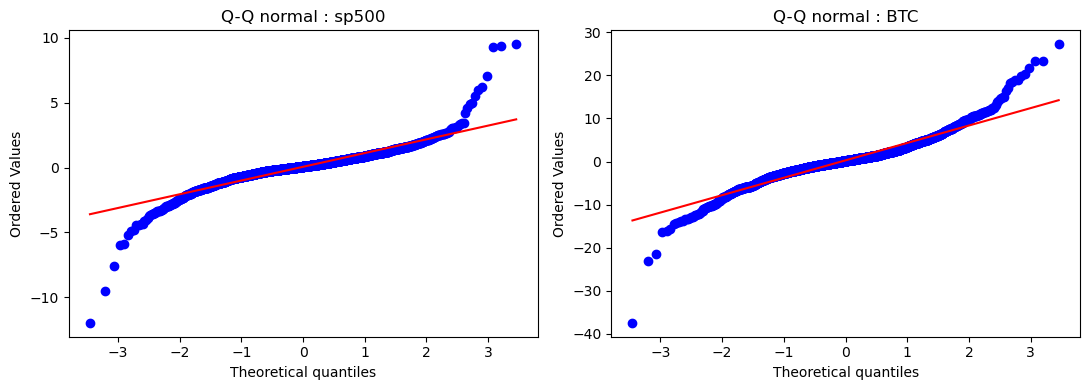

In [164]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ["sp500", "BTC"]):
    stats.probplot(Rt[col] , dist="norm", plot=ax)
    ax.set_title(f"Q-Q normal : {col}")
plt.tight_layout()
plt.show()

Les graphiques Q-Q des deux actifs dessinent une forme en S caractéristique : les points suivent la droite de la loi normale au centre de la distribution, mais s’en écartent fortement aux deux extrémités. Les pertes et les gains extrêmes sont bien plus importants que ne le prévoit la loi normale : environ −12 % au pire pour le S&P 500 contre −3,6 % attendu, et −37 % pour le Bitcoin contre −14 %. Les rendements présentent donc des queues épaisses, ce qui invalide l’hypothèse de normalité.

Rapportées à leur volatilité, ces queues sont plus épaisses pour le S&P 500 que pour le Bitcoin, ce qui est cohérent avec l’écart plus important entre VaR normale et VaR historique observé pour le S&P 500. Une VaR fondée sur la loi normale sous-estime donc les pertes extrêmes des deux actifs, comme l’a confirmé le backtesting.

In [ ]:
#5) Matrice de nuages de points

La matrice de nuages de points montre, en une seule image, comment les actifs bougent les uns par rapport aux autres. C’est l’équivalent visuel de la corrélation
À quoi elle sert en risque

1. Mesurer la diversification. Un portefeuille est protégé si ses actifs ne chutent pas en même temps. Un nuage rond signifie une bonne diversification : les pertes de l’un sont souvent compensées par l’autre.

2. Voir ce que la corrélation cache. La corrélation résume le nuage en un seul chiffre, qui peut être trompeur. Deux actifs peuvent avoir une corrélation faible en temps normal, mais chuter ensemble les jours de crise. Sur le nuage, on regarde le coin en bas à gauche : y a-t-il des points où les deux actifs ont fortement baissé le même jour ? C’est ce qui s’est passé en mars 2020.

3. Préparer la VaR d’un portefeuille. La VaR de plusieurs actifs dépend de leur corrélation. Si on la sous-estime en crise, on sous-estime le risque du portefeuille. C’est la même erreur que la loi normale, mais entre actifs.

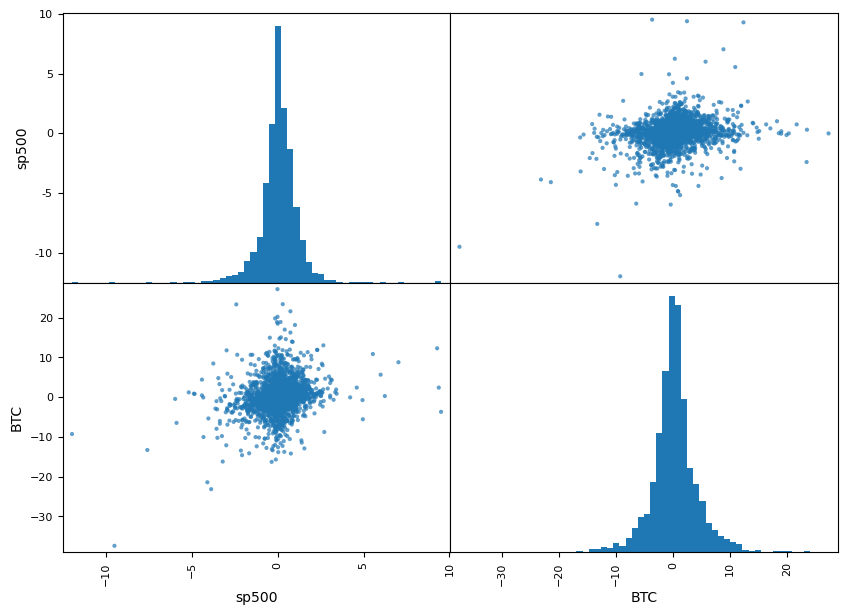

In [172]:
pd.plotting.scatter_matrix(Rt, figsize=(10, 7), alpha=0.7, diagonal="hist",hist_kwds={"bins": 60})
plt.show()

Les nuages, hors de la diagonale

1. La forme générale est presque ronde, avec peut-être une très légère inclinaison vers le haut à droite. Les deux actifs bougent largement indépendamment au quotidien : un jour de hausse du S&P 500 ne dit presque rien du Bitcoin. La corrélation devrait donc être positive mais faible.

2. Le cœur du nuage est très dense : la grande majorité des jours sont calmes pour les deux actifs.

3. Quelques points isolés sortent dans le coin en bas à gauche. Sur le graphique en haut à droite, on voit un point tout en bas à gauche, et quelques autres sous le nuage. Ce sont des journées où les deux actifs ont fortement chuté en même temps. Le plus extrême est très probablement le 12 mars 2020, le jour où le S&P 500 a perdu environ 10 % et le Bitcoin plus de 35 %.

Ce que ça veut dire en risque

C’est le message clé : en temps normal, le Bitcoin diversifie un portefeuille d’actions, puisque leur lien est faible. Mais pendant les krachs, ils chutent ensemble : la diversification disparaît précisément au moment où on en a besoin.

Lire les nuages 
D’abord : que représente un point ?

Chaque point est un jour. Sa position horizontale est le rendement d’un actif ce jour-là, et sa position verticale celui de l’autre actif. Le centre du nuage, autour de (0, 0), correspond aux jours calmes pour les deux.

Indice 2 : la forme du nuage
Forme	                                       Corrélation	                      Lecture
rond	                                        proche de 0	                  pas de lien entre les actifs
ovale incliné vers le haut à droite	            positive	                      ils bougent ensemble
ovale incliné vers le bas à droite              négative	                  ils bougent en sens opposé
presque une ligne	                            proche de +1 ou −1	          ils bougent presque à l’identiqu

Indice 3 : l’étalement sur chaque axe
Un nuage plus étalé dans une direction que dans l’autre montre que l’un des actifs est plus volatil. Sur ta matrice, regarde les graduations : le nuage s’étend bien plus loin sur l’axe du Bitcoin que sur celui du S&P 500. C’est sa volatilité trois fois plus forte.

Indice 4 : la densité
Les zones foncées montrent où se trouvent la plupart des jours. Un cœur très dense et serré, entouré de points rares, c’est encore la signature des queues épaisses : beaucoup de jours calmes, et quelques jours extrêmes.

Indice 5 : les points isolés, et surtout leurs coins
C’est l’indice le plus important en risque. Regarde où se trouvent les points éloignés du nuage :
dans le coin en bas à gauche : les deux actifs ont chuté fortement le même jour. C’est le danger : la diversification disparaît ;
le long d’un seul axe : un seul actif a connu une journée extrême, l’autre est resté calme. Là, la diversification a joué.
Un nuage peut être globalement rond, avec une corrélation faible, mais avoir plusieurs points dans le coin en bas à gauche. Ces quelques jours suffisent à faire perdre beaucoup d’argent à un portefeuille « diversifié ». C’est pourquoi on ne se contente jamais de la corrélation seule : on regarde aussi le nuage.


Lire histogramme 

Point 1 : le centre
Où se trouve la barre la plus haute ? Pour des rendements quotidiens, presque toujours autour de 0 : la plupart des jours, le marché bouge très peu. Un centre légèrement à droite de 0 traduit une petite tendance à la hausse sur la période.

Point 2 : la largeur
Plus l’histogramme est étalé, plus l’actif est volatil. Compare les graduations des deux histogrammes : celui du Bitcoin s’étend bien plus loin que celui du S&P 500. C’est la volatilité, environ trois fois plus forte, vue sous forme de graphique.

Point 3 : la forme du pic
Compare-le à une cloche normale. Un pic étroit et très haut signifie beaucoup plus de jours très calmes que ne le prévoit la loi normale. C’est ce que tu observes sur les deux actifs

Point 4 : les queues
Regarde les extrémités, à gauche et à droite. Des barres minuscules, mais présentes très loin du centre, signalent des journées extrêmes rares. Pic étroit et queues longues : c’est la signature des queues épaisses, que tu as mesurée avec la kurtosis et le Q-Q plot.

Point 5 : la symétrie
La queue de gauche, celle des pertes, est-elle plus longue que celle de droite ?
Plus longue à gauche : les pires journées sont plus violentes que les meilleures. C’est ce que tu as trouvé pour le S&P 500 : −12 % au pire contre +9,5 % au mieux ;
Plus longue à droite : c’est l’inverse.